<a href="https://colab.research.google.com/github/Rogerkamana/Assignment4_rk/blob/main/Assignment_8_Supervised_Learning_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 8: Supervised Learning Classification
## Breast Cancer Classification
The title and model requirements specify classification despite references to regression. Malignant is encoded as the positive class (1). This is an educational model, not a clinical diagnostic tool.

## 1. Dataset Selection and Preprocessing

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
import joblib

# Load public dataset and encode malignant as 1.
data = load_breast_cancer(as_frame=True)
df = data.data.copy()
df['malignant'] = 1 - data.target
print('Original shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Duplicates:', df.duplicated().sum())
df = df.drop_duplicates()
X = df.drop(columns='malignant')
y = df['malignant']
# All predictors are numeric; no categorical feature encoding is needed.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)
print('Train/test:', X_train.shape, X_test.shape)
print(df.head().round(3).to_string())

Original shape: (569, 31)
Missing values: 0
Duplicates: 0
Train/test: (455, 30) (114, 30)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean symmetry  mean fractal dimension  radius error  texture error  perimeter error  area error  smoothness error  compactness error  concavity error  concave points error  symmetry error  fractal dimension error  worst radius  worst texture  worst perimeter  worst area  worst smoothness  worst compactness  worst concavity  worst concave points  worst symmetry  worst fractal dimension  malignant
0        17.99         10.38          122.80     1001.0            0.118             0.278           0.300                0.147          0.242                   0.079         1.095          0.905            8.589      153.40             0.006              0.049            0.054                 0.016           0.030                    0.006         25.38          17.33           1

## 2. Exploratory Data Analysis (EDA)
Use training data for exploration to avoid influencing decisions with the test set.

       mean radius  mean texture  ...  worst symmetry  worst fractal dimension
count       455.00        455.00  ...          455.00                   455.00
mean         14.17         19.42  ...            0.29                     0.08
std           3.58          4.29  ...            0.06                     0.02
min           6.98          9.71  ...            0.16                     0.06
25%          11.71         16.34  ...            0.25                     0.07
50%          13.34         18.90  ...            0.28                     0.08
75%          15.93         21.83  ...            0.32                     0.09
max          28.11         39.28  ...            0.66                     0.21

[8 rows x 30 columns]
malignant
0    285
1    170
Name: count, dtype: int64


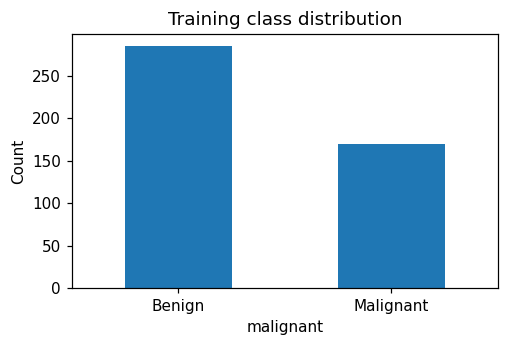

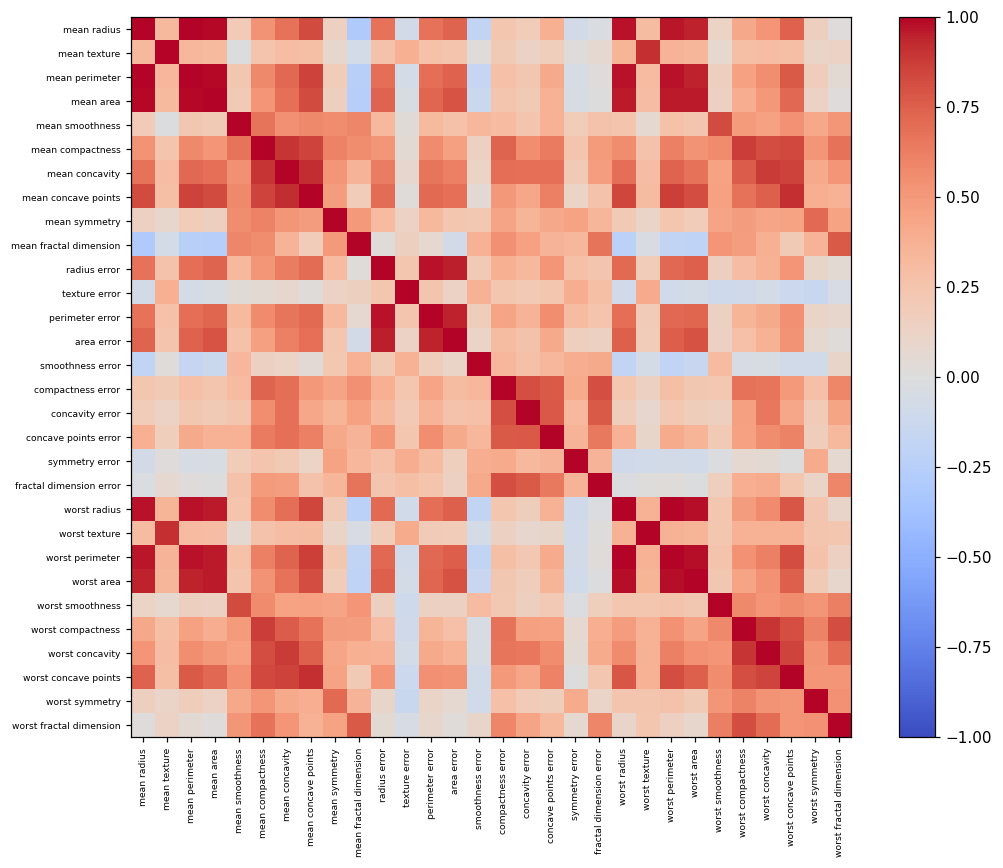

In [ ]:
print(X_train.describe().round(2))
print(y_train.value_counts())
fig, ax = plt.subplots(figsize=(5,3))
y_train.map({0:'Benign',1:'Malignant'}).value_counts().plot.bar(ax=ax, rot=0)
ax.set(ylabel='Count', title='Training class distribution'); plt.show()
fig, ax = plt.subplots(figsize=(10,8))
cor = X_train.corr()
im = ax.imshow(cor, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(cor)), cor.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(cor)), cor.columns, fontsize=6)
fig.colorbar(im); plt.tight_layout(); plt.show()

Benign cases are more common. Radius, perimeter and area are strongly related, suggesting redundancy. Scaling and regularization help logistic regression; random forests can capture nonlinear relationships. Stratification preserves class proportions.

## 3. Model Implementation and Evaluation

In [ ]:
models = {
 'Logistic Regression': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)),
 'Random Forest': make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1))
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    # Select using training-only cross-validation ROC-AUC.
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc').mean()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:,1]
    rows.append([name, cv_auc, accuracy_score(y_test,pred), precision_score(y_test,pred), recall_score(y_test,pred), f1_score(y_test,pred), roc_auc_score(y_test,prob)])
results = pd.DataFrame(rows, columns=['Model','CV AUC','Accuracy','Precision','Recall','F1','ROC-AUC']).set_index('Model')
best = results['CV AUC'].idxmax()
print('Selected model:', best)
print(results.round(4).to_string())


Selected model: Logistic Regression
                     CV AUC  Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                                    
Logistic Regression  0.9958    0.9649      0.975  0.9286  0.9512   0.9960
Random Forest        0.9889    0.9649      1.000  0.9048  0.9500   0.9942


## 4. Model Interpretation and Inference

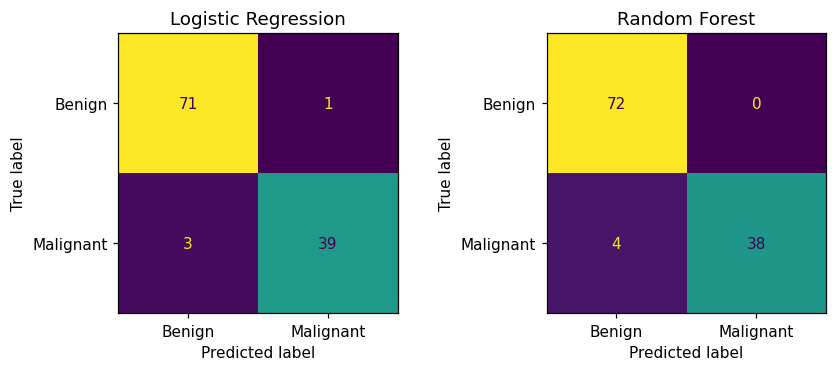

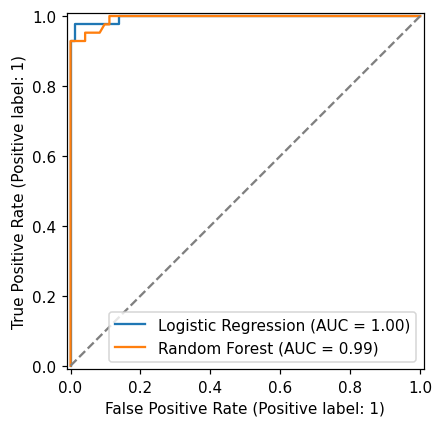

Logistic Regression: TN=71, FP=1, FN=3, TP=39
Random Forest: TN=72, FP=0, FN=4, TP=38
Selected model: Logistic Regression | Test AUC: 0.996


In [ ]:
fig, axes = plt.subplots(1,2,figsize=(8,3.5))
for (name, model), ax in zip(models.items(), axes):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=['Benign','Malignant'], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(5,4))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0,1],[0,1],'--',color='gray'); plt.tight_layout()
plt.show()
for name, model in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(X_test)).ravel()
    print(f'{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}')
print('Selected model:', best, '| Test AUC:', round(results.loc[best,'ROC-AUC'],4))

## 5. Deployment and Monitoring
Package the fitted pipeline and feature schema with joblib. A FastAPI service could validate the 30 numeric inputs, reject malformed or non-finite values, and return a probability and model version. Use authenticated HTTPS, access controls, and privacy-preserving logs. Monitor latency, errors, missingness, feature and prediction drift, and delayed-label recall, precision and AUC. Investigate drift before retraining; validate new versions and retain rollback capability. Clinical use would require independent validation, calibration, appropriate approvals and human oversight.

In [ ]:
# Save the complete preprocessing and model pipeline.
joblib.dump({'model': models[best], 'features': list(X.columns), 'positive_class': 'malignant'}, 'breast_cancer_model.joblib')
# Demonstrate inference on a held-out example (not a clinical recommendation).
example = X_test.iloc[[0]]
bundle = joblib.load('breast_cancer_model.joblib')
prediction = bundle['model'].predict(example[bundle['features']])[0]
probability = bundle['model'].predict_proba(example[bundle['features']])[0, 1]
print('Predicted class:', {0: 'Benign', 1: 'Malignant'}[prediction])
print(f'Malignant probability: {probability:.3f}')

Predicted class: Benign
Malignant probability: 0.000


## 6. Report Writing
See the accompanying two-page PDF report for the dataset, preprocessing, findings, evaluation and deployment plan.
